# START HERE TO REVIEW SHARED LABELS
This notebook regenerates **automatic proposals**, not human-approved answers. Review audio and note overlays together; record decisions in review_queue.csv. Save actual curated targets in a NEW separately versioned CSV (for example train_targets_reviewed_v1.csv), never in train_targets.csv because rerunning rebuilds it.

The group must agree on correspondence policy and usable labels before fitting. Queenie has zero pairs under the current rule; revise that rule only through an agreed, separately versioned change. Starters still load provisional targets until explicitly changed to the approved reviewed file. Approval is not automatic. Final test stays locked.

# Shared correction handover: review the answer sheet first

This notebook uses the frozen original tuning_001 Basic Pitch predictions (onset 0.99) to prepare **provisional training labels** for Queenie, Felicia, Le Xin and Hann Qian. These are transparent heuristic proposals, not human-confirmed truth. No correction classifier is trained. No final-test audio or labels are loaded.

**Read this before training:** strict note F1 tells us whether a note already matches. Correction labels ask which event a prediction might correspond to. Those are different questions. A wrong-pitch or late note must not automatically become a deletion target.

You will see actual coverage counts, group review examples with playable audio, and the no-correction baseline. Ambiguous notes stay in the tables and in whole-transcription evaluation. They are not silently discarded.


## 1. Load the frozen input version

We record the selected decoder and fingerprints. Everyone must use this same baseline. If it changes later, create a new version rather than silently replacing teammates' inputs.

In [1]:
from pathlib import Path
import sys,json,hashlib
import pandas as pd
import numpy as np
from IPython.display import display,Markdown,Audio,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents,Path.cwd()/'GTSinger_100_unique_sample'] if (p/'selected_100.csv').exists())
sys.path.insert(0,str(ROOT/'notebooks'))
import bp_experiment as exp
import bp_tuning_core as core
from build_correction_handover import build_artifacts
OUT=ROOT/'basic_pitch_runs/correction_handover'; RUN=OUT
train_pred=json.loads((RUN/'selected_predictions_train.json').read_text())
val_pred=json.loads((RUN/'selected_predictions_val.json').read_text())
rows=exp.inputs(); train=[r for r in rows if r['split']=='train']
refs,audit=exp.references(train)
assert not audit['issues']
assert set(train_pred)=={r['recording_id'] for r in train}
assert set(val_pred)=={r['recording_id'] for r in rows if r['split']=='val'}
source={name:exp.sha(RUN/name) for name in ['selected_predictions_train.json','selected_predictions_val.json']}
lock_path=OUT/'input_version.json'
if lock_path.exists():
    assert json.loads(lock_path.read_text())['prediction_sha256']==source, 'Frozen handover inputs changed'
else:
    lock_path.write_text(json.dumps(dict(version='correction_handover_tuning001_onset099',prediction_sha256=source,labels_approved=False,test_enabled=False),indent=2))
display(pd.DataFrame([dict(split='train',recordings=len(train_pred)),dict(split='val features only',recordings=len(val_pred))]))
print('No test inference or reference parsing. No validation correction labels.')

,split,recordings
0,train,534
1,val features only,160


No test inference or reference parsing. No validation correction labels.


## 2. Build provisional relationships — do not confuse these with final answers

The proposal policy connects events whose time intervals overlap. It only proposes one-to-one repair when there is a unique overlap on both sides, overlap covers at least 60% of the shorter event, starts differ by at most 0.20 seconds, durations differ by no more than a factor of three, and pitches differ by at most an octave. Strong overlaps can therefore support a wrong-pitch label.

A merge proposal needs same-pitch fragments corresponding to just one reference, with nearby boundaries (gaps from -0.02 to 0.06 seconds), at least 60% union coverage of that reference and outer endpoints within 0.20 seconds. Separate repeated reference notes are not automatically merged. An isolated event more than 0.20 seconds away from every reference interval is a **spurious candidate**, not proven false audio content. Difficult overlaps, nearby unmatched events and possible splits remain unresolved.

These thresholds are initial conservative engineering choices, **not validated universal rules**. They favour easier cases and can miss severe timing/pitch errors. Your group must review the examples and coverage before fitting correction models. No annotation itself is edited.

In [2]:
summary=build_artifacts(OUT,rows,{**train_pred,**val_pred},refs)
features=pd.read_csv(OUT/'train_features.csv')
targets=pd.read_csv(OUT/'train_targets.csv')
pairs=pd.read_csv(OUT/'merge_candidates.csv')
pair_targets=pd.read_csv(OUT/'merge_targets.csv')
display(pd.DataFrame(list(summary['training_relationships'].items()),columns=['relationship','notes']))
display(pd.DataFrame(list(summary['merge_labels'].items()),columns=['merge_label_or_unresolved','pairs']))
print(json.dumps(summary,indent=2))

,relationship,notes
0,ambiguous,6383
1,one_to_one,946
2,split_candidate,98
3,spurious_candidate,196


,merge_label_or_unresolved,pairs


{
  "train_notes": 7623,
  "val_notes": 2329,
  "training_relationships": {
    "ambiguous": 6383,
    "one_to_one": 946,
    "split_candidate": 98,
    "spurious_candidate": 196
  },
  "training_label_status": {
    "unresolved": 6481,
    "provisional_auto": 1142
  },
  "merge_candidates": 0,
  "merge_labels": {},
  "false_labels": {
    "None": 6481,
    "0": 946,
    "1": 196
  },
  "test_included": false,
  "group_review_approved": false,
  "labels": "PROVISIONAL_HEURISTIC_NOT_HUMAN_GROUND_TRUTH"
}


## 3. Show exactly which task labels are usable

Features are information available from Basic Pitch predictions. Targets are derived from references and must never enter model input X. Pitch and timing targets can overlap. Fragments are not labelled as false-note deletions.

The simple first feature set is note timing, pitch, amplitude and neighbouring gaps. It contains no audio-derived pitch/onset evidence beyond Basic Pitch itself, so it is a starter, not a claim that these features suffice for difficult corrections. IDs, split, reference values and label status are not predictive features.

Below, usable means the heuristic supplied a provisional target—not that a human approved it. False-note labels emphasize isolated events and one-to-one matches; reported classifier scores on that subset will not represent every kind of error.

In [3]:
coverage=[]
for owner,fields in [('Felicia',['false_note']),('Le Xin',['start_delta','end_delta']),('Hann Qian',['pitch_delta'])]:
    usable=targets[fields].notna().all(axis=1)
    coverage.append(dict(owner=owner,total_notes=len(targets),provisional_targets=int(usable.sum()),unresolved_or_out_of_scope=int((~usable).sum())))
display(pd.DataFrame(coverage))
for label in ['false_note','wrong_start','wrong_end','wrong_pitch']:
    print(label,targets[label].value_counts(dropna=False).to_dict())
print('Queenie merge targets:',pair_targets['merge'].value_counts(dropna=False).to_dict())
assert set(features.note_id)==set(targets.note_id)
assert set(features.split)=={'train'}
assert not {'reference_pitch','false_note','relationship'}.intersection(features.columns)
print('Group review has NOT approved these labels.')

,owner,total_notes,provisional_targets,unresolved_or_out_of_scope
0,Felicia,7623,1142,6481
1,Le Xin,7623,946,6677
2,Hann Qian,7623,946,6677


false_note {nan: 6481, 0.0: 946, 1.0: 196}
wrong_start {nan: 6677, 1.0: 562, 0.0: 384}
wrong_end {nan: 6677, 0.0: 681, 1.0: 265}
wrong_pitch {nan: 6677, 0.0: 870, 1.0: 76}
Queenie merge targets: {}
Group review has NOT approved these labels.


## 4. Listen and inspect representative training examples

Blue lines are reference notes; orange lines are Basic Pitch notes. Horizontal direction is time, vertical direction is pitch. Check whether the proposed relationship agrees with the audio and the supplied annotations.

Examples are selected deterministically to cover proposed relationship categories and languages—not to make performance look good. They are a review set, not an unbiased statistical sample. Playback is available below; generating this notebook does not imply a human has listened or approved.

Fill `review_queue.csv` with accept/reject/uncertain, corrected relationship, reviewer name and reason. Leave ambiguous examples unresolved until agreed. If you revise the policy, version it and rebuild all TRAIN labels consistently before training.

### Japanese — 0042c92327569dbbb243 | Proposals: {'ambiguous': 8, 'one_to_one': 1}

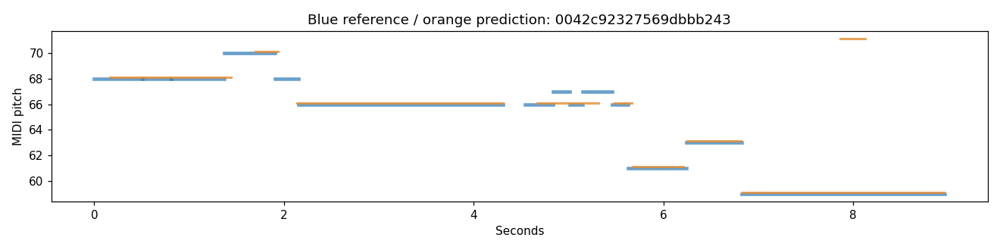

,note_id,start,end,pitch,relationship,false_note,start_delta,pitch_delta
4614,0042c92327569dbbb243:n00000,0.162540,1.439637,68,ambiguous,NaN,NaN,NaN
4615,0042c92327569dbbb243:n00001,1.695057,1.938866,70,ambiguous,NaN,NaN,NaN
4616,0042c92327569dbbb243:n00002,2.137520,4.309869,66,ambiguous,NaN,NaN,NaN
4617,0042c92327569dbbb243:n00003,4.669779,5.319937,66,ambiguous,NaN,NaN,NaN
4618,0042c92327569dbbb243:n00004,5.482477,5.668237,66,ambiguous,NaN,NaN,NaN
4619,0042c92327569dbbb243:n00005,5.679847,6.215190,61,ambiguous,NaN,NaN,NaN
4620,0042c92327569dbbb243:n00006,6.250020,6.818908,63,one_to_one,0.0,-0.00702,0.0
4621,0042c92327569dbbb243:n00007,6.830518,8.956428,59,ambiguous,NaN,NaN,NaN
4622,0042c92327569dbbb243:n00008,7.863806,8.132120,71,ambiguous,NaN,NaN,NaN


### Russian — 0923ef553b49fff32404 | Proposals: {'one_to_one': 2, 'ambiguous': 2, 'split_candidate': 1}

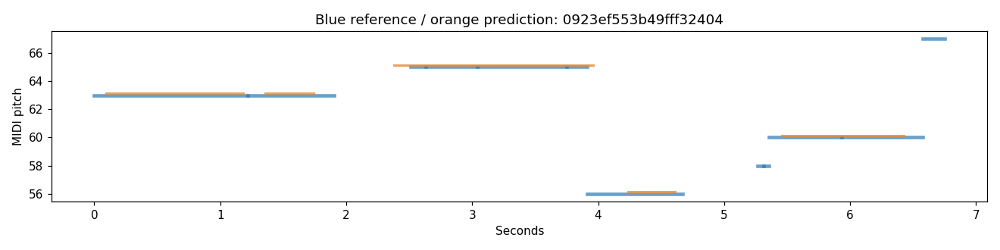

,note_id,start,end,pitch,relationship,false_note,start_delta,pitch_delta
6085,0923ef553b49fff32404:n00000,0.092880,1.184218,63,one_to_one,0.0,-0.092880,0.0
6086,0923ef553b49fff32404:n00001,1.358367,1.741497,63,one_to_one,0.0,-0.137367,0.0
6087,0923ef553b49fff32404:n00002,2.381329,3.960286,65,ambiguous,NaN,NaN,NaN
6088,0923ef553b49fff32404:n00003,4.240210,4.611729,56,ambiguous,NaN,NaN,NaN
6089,0923ef553b49fff32404:n00004,5.459257,6.424169,60,split_candidate,NaN,NaN,NaN


### Korean — 01ec334d8f022982172f | Proposals: {'ambiguous': 9, 'spurious_candidate': 1, 'one_to_one': 1}

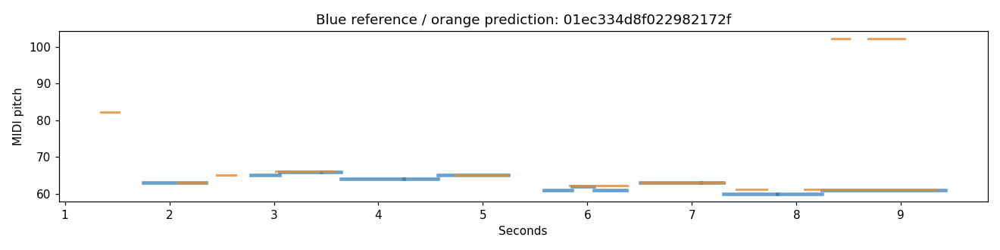

,note_id,start,end,pitch,relationship,false_note,start_delta,pitch_delta
5346,01ec334d8f022982172f:n00000,1.346757,1.520907,82,spurious_candidate,1.0,NaN,NaN
5347,01ec334d8f022982172f:n00001,2.079470,2.346499,63,ambiguous,NaN,NaN,NaN
5348,01ec334d8f022982172f:n00002,2.450989,2.636749,65,ambiguous,NaN,NaN,NaN
5349,01ec334d8f022982172f:n00003,3.019878,3.577157,66,ambiguous,NaN,NaN,NaN
5350,01ec334d8f022982172f:n00004,4.727829,5.227058,65,one_to_one,0.0,-0.155829,0.0
5351,01ec334d8f022982172f:n00005,5.830776,6.377729,62,ambiguous,NaN,NaN,NaN
5352,01ec334d8f022982172f:n00006,6.517049,7.306527,63,ambiguous,NaN,NaN,NaN
5353,01ec334d8f022982172f:n00007,7.422627,7.712877,61,ambiguous,NaN,NaN,NaN
5354,01ec334d8f022982172f:n00008,8.074070,9.327947,61,ambiguous,NaN,NaN,NaN
5355,01ec334d8f022982172f:n00009,8.341099,8.503639,102,ambiguous,NaN,NaN,NaN


### Chinese — 010b7f914b8d864c0d80 | Proposals: {'ambiguous': 14}

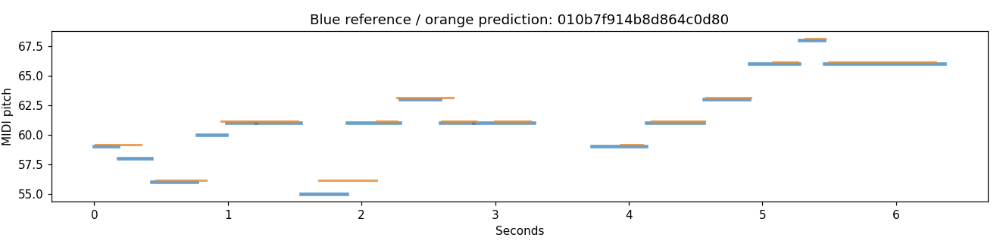

,note_id,start,end,pitch,relationship,false_note,start_delta,pitch_delta
449,010b7f914b8d864c0d80:n00000,0.011610,0.348299,59,ambiguous,NaN,NaN,NaN
450,010b7f914b8d864c0d80:n00001,0.464399,0.835918,56,ambiguous,NaN,NaN,NaN
451,010b7f914b8d864c0d80:n00002,0.952018,1.520907,61,ambiguous,NaN,NaN,NaN
452,010b7f914b8d864c0d80:n00003,1.683447,2.114300,56,ambiguous,NaN,NaN,NaN
453,010b7f914b8d864c0d80:n00004,2.114300,2.265229,61,ambiguous,NaN,NaN,NaN
454,010b7f914b8d864c0d80:n00005,2.265229,2.683189,63,ambiguous,NaN,NaN,NaN
455,010b7f914b8d864c0d80:n00006,2.601919,2.857338,61,ambiguous,NaN,NaN,NaN
456,010b7f914b8d864c0d80:n00007,2.996658,3.263688,61,ambiguous,NaN,NaN,NaN
457,010b7f914b8d864c0d80:n00008,3.937066,4.100890,59,ambiguous,NaN,NaN,NaN
458,010b7f914b8d864c0d80:n00009,4.170550,4.565289,61,ambiguous,NaN,NaN,NaN


### English — 154869806f57c27ee679 | Proposals: {'ambiguous': 3, 'one_to_one': 1, 'split_candidate': 1, 'spurious_candidate': 1}

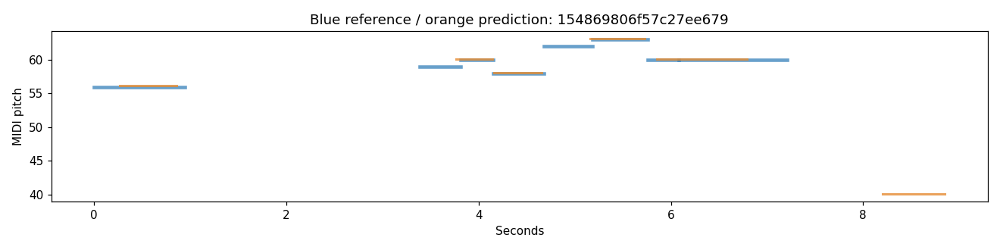

,note_id,start,end,pitch,relationship,false_note,start_delta,pitch_delta
1326,154869806f57c27ee679:n00000,0.267029,0.859138,56,ambiguous,NaN,NaN,NaN
1327,154869806f57c27ee679:n00001,3.762917,4.147330,60,ambiguous,NaN,NaN,NaN
1328,154869806f57c27ee679:n00002,4.158940,4.658169,58,one_to_one,0.0,-0.00794,0.0
1329,154869806f57c27ee679:n00003,5.157398,5.726287,63,ambiguous,NaN,NaN,NaN
1330,154869806f57c27ee679:n00004,5.853996,6.795688,60,split_candidate,NaN,NaN,NaN
1331,154869806f57c27ee679:n00005,8.201780,8.851938,40,spurious_candidate,1.0,NaN,NaN


### French — 04a3679788645e95470f | Proposals: {'one_to_one': 6, 'ambiguous': 6}

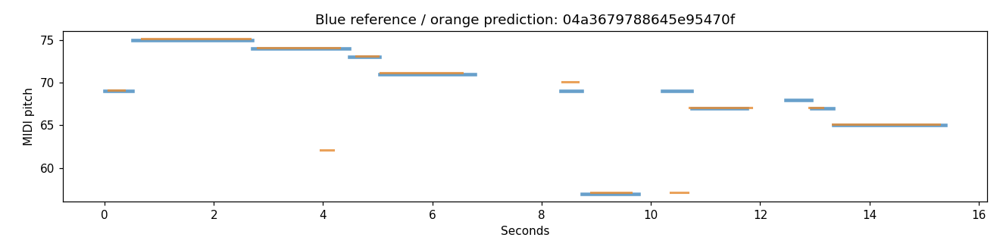

,note_id,start,end,pitch,relationship,false_note,start_delta,pitch_delta
1677,04a3679788645e95470f:n00000,0.069660,0.359909,69,one_to_one,0.0,-0.069660,0.0
1678,04a3679788645e95470f:n00001,0.684989,2.659969,75,one_to_one,0.0,-0.171989,0.0
1679,04a3679788645e95470f:n00002,2.799288,4.298259,74,ambiguous,NaN,NaN,NaN
1680,04a3679788645e95470f:n00003,3.948676,4.193770,62,ambiguous,NaN,NaN,NaN
1681,04a3679788645e95470f:n00004,4.600119,5.006468,73,one_to_one,0.0,-0.123119,0.0
1682,04a3679788645e95470f:n00005,5.041298,6.540269,71,one_to_one,0.0,-0.004298,0.0
1683,04a3679788645e95470f:n00006,8.375929,8.666179,70,one_to_one,0.0,-0.030929,-1.0
1684,04a3679788645e95470f:n00007,8.898378,9.641417,57,one_to_one,0.0,-0.165378,0.0
1685,04a3679788645e95470f:n00008,10.350909,10.675989,57,ambiguous,NaN,NaN,NaN
1686,04a3679788645e95470f:n00009,10.699209,11.836986,67,ambiguous,NaN,NaN,NaN


### German — 03029a04317f9a3efcaf | Proposals: {'ambiguous': 12, 'one_to_one': 2}

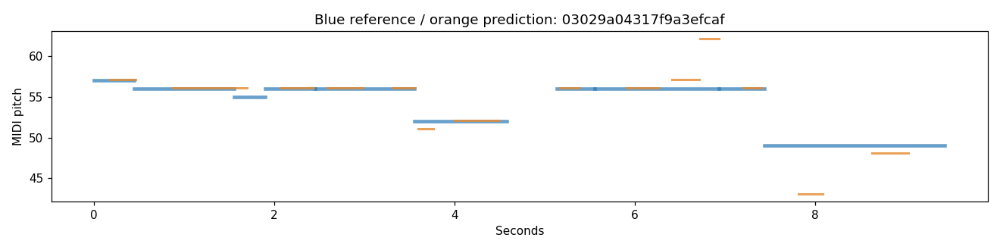

,note_id,start,end,pitch,relationship,false_note,start_delta,pitch_delta
2745,03029a04317f9a3efcaf:n00000,0.174150,0.464399,57,ambiguous,NaN,NaN,NaN
2746,03029a04317f9a3efcaf:n00001,0.870748,1.695057,56,ambiguous,NaN,NaN,NaN
2747,03029a04317f9a3efcaf:n00002,2.067860,2.439379,56,one_to_one,0.0,-0.165860,0.0
2748,03029a04317f9a3efcaf:n00003,2.590309,2.985048,56,ambiguous,NaN,NaN,NaN
2749,03029a04317f9a3efcaf:n00004,3.310127,3.565547,56,ambiguous,NaN,NaN,NaN
2750,03029a04317f9a3efcaf:n00005,3.600377,3.762917,51,ambiguous,NaN,NaN,NaN
2751,03029a04317f9a3efcaf:n00006,3.996400,4.495629,52,ambiguous,NaN,NaN,NaN
2752,03029a04317f9a3efcaf:n00007,5.169008,5.389597,56,one_to_one,0.0,-0.035008,0.0
2753,03029a04317f9a3efcaf:n00008,5.912046,6.273239,56,ambiguous,NaN,NaN,NaN
2754,03029a04317f9a3efcaf:n00009,6.412559,6.714419,57,ambiguous,NaN,NaN,NaN


### Italian — 05d3ffaf82684e17cb50 | Proposals: {'ambiguous': 13, 'one_to_one': 3}

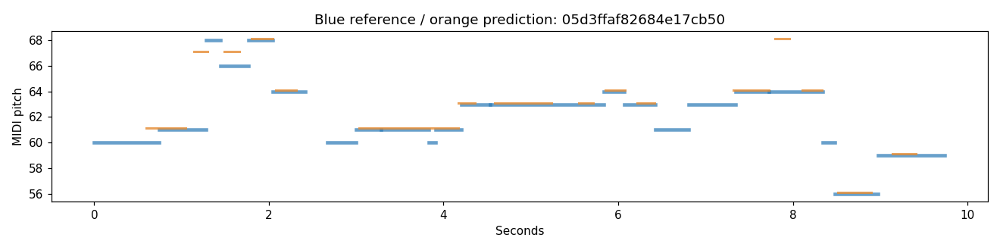

,note_id,start,end,pitch,relationship,false_note,start_delta,pitch_delta
4014,05d3ffaf82684e17cb50:n00000,0.592109,1.044898,61,ambiguous,NaN,NaN,NaN
4015,05d3ffaf82684e17cb50:n00001,1.137778,1.300317,67,ambiguous,NaN,NaN,NaN
4016,05d3ffaf82684e17cb50:n00002,1.486077,1.660227,67,one_to_one,0.0,-0.037077,-1.0
4017,05d3ffaf82684e17cb50:n00003,1.799546,2.044640,68,ambiguous,NaN,NaN,NaN
4018,05d3ffaf82684e17cb50:n00004,2.079470,2.311669,64,ambiguous,NaN,NaN,NaN
4019,05d3ffaf82684e17cb50:n00005,3.031488,4.170550,61,ambiguous,NaN,NaN,NaN
4020,05d3ffaf82684e17cb50:n00006,4.170550,4.356309,63,ambiguous,NaN,NaN,NaN
4021,05d3ffaf82684e17cb50:n00007,4.588509,5.238668,63,ambiguous,NaN,NaN,NaN
4022,05d3ffaf82684e17cb50:n00008,5.552137,5.714677,63,ambiguous,NaN,NaN,NaN
4023,05d3ffaf82684e17cb50:n00009,5.853996,6.075870,64,ambiguous,NaN,NaN,NaN


### Spanish — 0695c8c56f841c0b1f73 | Proposals: {'ambiguous': 30, 'one_to_one': 2}

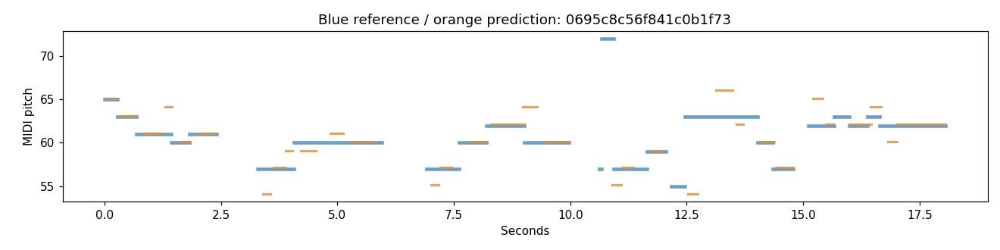

,note_id,start,end,pitch,relationship,false_note,start_delta,pitch_delta
7001,0695c8c56f841c0b1f73:n00000,0.023220,0.267029,65,one_to_one,0.0,-0.02322,0.0
7002,0695c8c56f841c0b1f73:n00001,0.301859,0.684989,63,ambiguous,NaN,NaN,NaN
7003,0695c8c56f841c0b1f73:n00002,0.835918,1.242268,61,ambiguous,NaN,NaN,NaN
7004,0695c8c56f841c0b1f73:n00003,1.300317,1.439637,64,ambiguous,NaN,NaN,NaN
7005,0695c8c56f841c0b1f73:n00004,1.625397,1.834376,60,ambiguous,NaN,NaN,NaN
7006,0695c8c56f841c0b1f73:n00005,1.973696,2.392939,61,ambiguous,NaN,NaN,NaN
7007,0695c8c56f841c0b1f73:n00006,3.391397,3.553937,54,ambiguous,NaN,NaN,NaN
7008,0695c8c56f841c0b1f73:n00007,3.623597,3.890626,57,ambiguous,NaN,NaN,NaN
7009,0695c8c56f841c0b1f73:n00008,3.879016,4.031230,59,ambiguous,NaN,NaN,NaN
7010,0695c8c56f841c0b1f73:n00009,4.216990,4.542069,59,ambiguous,NaN,NaN,NaN


Review recordings: 9 Proposed note reviews: 119


In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
joined=features.merge(targets,on='note_id',validate='one_to_one')
metadata={r['recording_id']:r for r in train}
review_ids=[]
for relationship,group in joined.groupby('relationship'):
    rid=sorted(group.recording_id.unique())[0]
    if rid not in review_ids: review_ids.append(rid)
for rid in sorted(pairs.recording_id.unique())[:3]:
    if rid not in review_ids: review_ids.append(rid)
for language in sorted({r['language'] for r in train}):
    candidates=sorted(r['recording_id'] for r in train if r['language']==language)
    if not any(metadata[r]['language']==language for r in review_ids): review_ids.append(candidates[0])
queue=[]
for rid in review_ids:
    r=metadata[rid]
    frame=joined[joined.recording_id==rid]
    display(Markdown('### '+r['language']+' — '+rid+' | Proposals: '+str(frame.relationship.value_counts().to_dict())))
    display(Audio(filename=str(ROOT/r['audio_path']),embed=True))
    fig,ax=plt.subplots(figsize=(12,3))
    for s,e,p in refs[rid]: ax.plot([s,e],[p,p],color='#2878B5',lw=3,alpha=.7)
    for s,e,p,a in train_pred[rid]: ax.plot([s,e],[p+.12,p+.12],color='#E58B32',lw=2,alpha=.8)
    ax.set(xlabel='Seconds',ylabel='MIDI pitch',title='Blue reference / orange prediction: '+rid)
    fig.tight_layout(); image=OUT/(rid+'_review.png'); fig.savefig(image,dpi=110); plt.close(fig)
    display(Image(filename=str(image)))
    display(frame[['note_id','start','end','pitch','relationship','false_note','start_delta','pitch_delta']].head(12))
    if (pairs.recording_id==rid).any():
        display(Markdown('**Queenie: review these candidate pairs; neither merge nor keep has been established automatically.**'))
        display(pairs[pairs.recording_id==rid].merge(pair_targets,on='pair_id'))
    for row in frame.itertuples(): queue.append(dict(note_id=row.note_id,recording_id=rid,proposed_relationship=row.relationship,decision='',corrected_relationship='',reviewer='',reason=''))
queue_path=OUT/'review_queue.csv'
if not queue_path.exists() or pd.read_csv(queue_path)[['decision','corrected_relationship','reviewer','reason']].isna().all().all(): pd.DataFrame(queue).to_csv(queue_path,index=False)
pair_review=OUT/'merge_review_queue.csv'
if not pair_review.exists():
    pairs.merge(pair_targets,on='pair_id').assign(decision='',reviewer='',reason='').to_csv(pair_review,index=False)
(OUT/'review_examples.json').write_text(json.dumps(review_ids,indent=2))
print('Review recordings:',len(review_ids),'Proposed note reviews:',len(queue))

## 5. Measure the unchanged transcription, including every training excerpt

This is the shared no-correction baseline, not a correction-model result. Score all recordings, including those with unresolved labels. Missing-note insertion and splitting a long note into several notes are not implemented by the four starter tasks.

The main F1 requires pitch plus start within 0.05 seconds; the stricter score also checks endings. Per-task metrics in the team notebooks measure different questions and cannot be compared as if they were the same F1.

In [5]:
metrics=[]
for row in train:
    rid=row['recording_id']
    metrics.append(dict(recording_id=rid,sample_id=row['sample_id'],**core.score_notes(refs[rid],train_pred[rid])))
songs,baseline=core.aggregate(metrics)
(OUT/'no_correction_training_baseline.json').write_text(json.dumps(baseline,indent=2))
pd.DataFrame(songs).to_csv(OUT/'no_correction_song_metrics.csv',index=False)
display(pd.DataFrame([baseline]))
print('Every training recording scored:',len(metrics))

,song_macro_f1,song_macro_offset_f1,song_macro_precision,song_macro_recall,micro_f1,songs,recordings
0,0.262758,0.153866,0.273301,0.258244,0.265211,60,534


Every training recording scored: 534


## 6. Handover checkpoint

**Prepared:** fixed input predictions, separated feature/target tables, provisional labels, candidate pairs, review audio/plots and team notebook interfaces.

**Not completed by automation:** human agreement on labels, each groupmate's trained model, choosing the best combined correction order, missing-note insertion/splitting, final-test evaluation.

Do not turn an unresolved label into zero. Do not use reference columns as features. Keep song groups intact in all folds; fit scaling and feature selection within the training fold. Once group review approves a label version, train task models, evaluate each alone, then evaluate the combined pipeline against the same unchanged baseline.

In [6]:
review_state=dict(approved=False,reason='Group review of provisional correspondences required before treating labels as ground truth',trained_correction_models=0,final_test_run=False)
state_path=OUT/'group_review_gate.json'
if not state_path.exists(): state_path.write_text(json.dumps(review_state,indent=2))
print(json.dumps(json.loads(state_path.read_text()),indent=2))
print('Frozen source preservation:',exp.frozen_check())

{
  "approved": false,
  "reason": "Group review of provisional correspondences required before treating labels as ground truth",
  "trained_correction_models": 0,
  "final_test_run": false
}


Frozen source preservation: {'passed': True, 'protected_files': 3439, 'changed_paths': []}
